In [21]:
# Import required libraries
import sys
#sys.path.append(stm_graph_path)
#import stm_graph
import os
import pandas as pd
import numpy as np
import datetime
from datetime import timedelta
import matplotlib.pyplot as plt
import contextily as ctx
!pip install pyarrow
import pyarrow

# Define the data and output directories
DATA_DIR = ""
CAMERA_DATASET = "yearly_red_light_cameras.csv"
REDLIGHT_DATASET = "all_red_light_tickets_geocoded.parquet"
CRASH_DATASET = "Motor_Vehicle_Collisions_from2016.csv"


OUTPUT_DIR = ""

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.0/29.0 MB 10.5 MB/s eta 0:00:00a 0:00:01


In [60]:
# Step 1: Read the raw data
print(f"Reading camera data from {CAMERA_DATASET}")
camera_df = pd.read_csv(CAMERA_DATASET, low_memory=False)

print(f"Reading raw crash incident data from {CRASH_DATASET}")
crash_df = pd.read_csv(CRASH_DATASET, low_memory=False)

print(f"Reading raw RED LIGHT with LATITUDE/LONGITUDE incident data from {REDLIGHT_DATASET}")
redlight_df = pd.read_parquet(REDLIGHT_DATASET, engine='pyarrow')


Reading camera data from yearly_red_light_cameras.csv
Reading raw crash incident data from Motor_Vehicle_Collisions_from2016.csv
Reading raw RED LIGHT with LATITUDE/LONGITUDE incident data from all_red_light_tickets_geocoded.parquet


In [61]:
#camera_df.head(10)
print("\nColumn names:")
print(redlight_df.columns.tolist())
redlight_df.head(10)

#crash_df['Violation Time'] = crash_df['Violation Time'].astype(int)




Column names:
['summons_number', 'issue_date', 'violation_time', 'violation_code', 'street_name', 'intersecting_street', 'violation_county', 'plate_id', 'registration_state', 'search_query', 'Latitude', 'Longitude']


,summons_number,issue_date,violation_time,violation_code,street_name,intersecting_street,violation_county,plate_id,registration_state,search_query,Latitude,Longitude
0,5092469481,2016-07-10,0143A,7,ALLERTON AVE (W/B) @,BARNES AVE,BX,GZH7067,NY,"ALLERTON AVE AND BARNES AVE, NEW YORK, NY",40.865510,-73.863525
1,5092451658,2016-07-08,0400P,7,ALLERTON AVE (W/B) @,BARNES AVE,BX,GZH7067,NY,"ALLERTON AVE AND BARNES AVE, NEW YORK, NY",40.865510,-73.863525
2,5093429077,2016-09-09,0102P,7,NORTHERN BLVD (E/B),@ MARATHON PKWY,QN,HHF9280,NY,"NORTHERN BLVD AND MARATHON PKWY, NEW YORK, NY",40.768397,-73.737528
3,5094755523,2016-12-18,0442P,7,NARROWS RD (W/B) @ C,LOVE RD,ST,W98HFL,NJ,"NARROWS RD AND C LOVE RD, NEW YORK, NY",40.610956,-74.098098
4,5093457784,2016-09-12,1146A,7,ATLANTIC AVE (W/B) @,KINGSTON AVE,BK,DTZ584,SC,"ATLANTIC AVE AND KINGSTON AVE, NEW YORK, NY",40.678094,-73.941372
5,5093709906,2016-09-30,0337P,7,CONEY ISLAND AVE (S/,B) @ DORCHESTER RD,BK,HDV1961,NY,"CONEY ISLAND AVE AND DORCHESTER RD, NEW YORK, NY",40.637289,-73.968221
6,5094348279,2016-11-25,0145P,7,REMSEN AVE (N/B) @ L,ENOX RD,BK,GMW1054,NY,"REMSEN AVE AND L ENOX RD, NEW YORK, NY",40.655854,-73.923375
7,5095118440,2017-01-24,0355P,7,CLASSON AVE (N/B) @,FLUSHING AVE,BK,GTC1972,NY,"CLASSON AVE AND FLUSHING AVE, NEW YORK, NY",40.698207,-73.961894
8,5095252200,2017-02-07,0130A,7,WILLIAMSBURG ST (S/B,) @ FLUSHING AVE,BK,HJJ4891,NY,"WILLIAMSBURG ST AND FLUSHING AVE, NEW YORK, NY",40.698062,-73.962819
9,5095654465,2017-03-16,0957P,7,CONEY ISLAND AVE (S/,B) @ DORCHESTER RD,BK,HNJ4580,NY,"CONEY ISLAND AVE AND DORCHESTER RD, NEW YORK, NY",40.637289,-73.968221


In [62]:
camera_loc_raw = []
for r in camera_df.itertuples(index=False):
    camera_loc_raw.append((r.Latitude, r.Longitude))
camera_location_pairs = list(dict.fromkeys(camera_loc_raw))
print(camera_location_pairs)

#only get indices which match
mask = pd.MultiIndex.from_frame(redlight_df[['Latitude', 'Longitude']]).isin(camera_location_pairs)
df_filtered = redlight_df[mask]
#basically pointless lol

df_first_only = df_filtered.sort_values(df_filtered.columns.tolist())\
          .drop_duplicates(subset=['Latitude','Longitude'], keep='first')


print(f"Dataset shape: {redlight_df.shape}")
print(f"Dataset shape: {df_first_only.shape}")
df_first_only.head(10)


[(40.76534581872, -73.744281359829), (40.836315979639, -73.869993981845), (40.575848003186, -74.119818030912), (40.680840979647, -73.975119979109), (40.883026984931, -73.853247023119), (40.646636989269, -73.924767958897), (40.655629011176, -74.006574998613), (40.820244979495, -73.890711029009), (40.769429314309, -73.910277827601), (40.868486017393, -73.842415005827), (40.736805019312, -73.877641965578), (40.658685011165, -73.890809013457), (40.73857460671, -73.887233461201), (40.67679801056, -73.843870020399), (40.666101989646, -73.828068959447), (40.610265103453, -74.097428123512), (40.735626817092, -73.923064923809), (40.609514001109, -73.75371896371), (40.613023001055, -74.158826989196), (40.607758998223, -74.132040019209), (40.698062018816, -73.962818781828), (40.770378020019, -73.917697991206), (40.862134211167, -73.929992566784), (40.607247995495, -73.96733402925), (40.58993400102, -73.804583034387), (40.67435158448, -73.801216862072), (40.869579981486, -73.826266012074), (40.675

,summons_number,issue_date,violation_time,violation_code,street_name,intersecting_street,violation_county,plate_id,registration_state,search_query,Latitude,Longitude
887608,1414737117,2017-12-31,0813P,7,ANTHONY AVE,E 130 ST,None,GFVR65,99,"ANTHONY AVE E 130 ST, NEW YORK, NY",40.724544,-73.932212
532764,1437238427,2018-01-17,0351P,7,BATTERY ST,WEST ST,NY,P869863,IL,"BATTERY ST WEST ST, NEW YORK, NY",40.706413,-74.017836
5910534,1490573471,2025-08-02,1244P,7,RANDALLS ISLAND,WARDS MEADOW,NY,BLANKPLATE,99,"RANDALLS ISLAND WARDS MEADOW, NEW YORK, NY",40.783851,-73.929187
5829256,1498692734,2025-07-03,0504P,7,HUTCHINSON RIVER PKW,FERRY POINT PARK,BX,BLANKPLATE,99,"HUTCHINSON RIVER PKW FERRY POINT PARK, NEW YOR...",40.811211,-73.836368
484537,5091822290,2016-05-27,0554P,7,EASTERN PKWY (W/B) @,HOWARD AVE,BK,VHM7588,VA,"EASTERN PKWY AND HOWARD AVE, NEW YORK, NY",40.669381,-73.920078
473722,5091822306,2016-05-29,0106P,7,ATLANTIC AVE (W/B) @,NOSTRAND AVE,BK,WNS7457,VA,"ATLANTIC AVE AND NOSTRAND AVE, NEW YORK, NY",40.678548,-73.949685
496664,5091822318,2016-05-29,0456P,7,KINGS HWY (E/B) @ NO,STRAND AVE,BK,JMH5987,PA,"KINGS HWY AND NO STRAND AVE, NEW YORK, NY",40.616170,-73.944866
485639,5091822320,2016-05-29,0457P,7,NORTHERN BLVD (E/B),@ DOUGLASTON PKWY,QN,GMT7071,NY,"NORTHERN BLVD AND DOUGLASTON PKWY, NEW YORK, NY",40.765346,-73.744281
490544,5091822331,2016-05-29,0634P,7,ATLANTIC AVE (E/B) @,BEDFORD AVE,BK,FDC4637,NY,"ATLANTIC AVE AND BEDFORD AVE, NEW YORK, NY",40.678793,-73.953014
498596,5091822343,2016-05-29,0635P,7,BORDEN AVE (E/B) @ G,REENPOINT AVE,QN,GCN7134,NY,"BORDEN AVE AND G REENPOINT AVE, NEW YORK, NY",40.736826,-73.931604


In [63]:
first_issue_date_dict = {}


#create a key-value dictionary for lat/longitude to match to date
for i in df_first_only.index:

    key = (df_first_only.at[i, 'Latitude'] ,df_first_only.at[i, 'Longitude']) #Rename columns accordingly
    value = (df_first_only.at[i, 'issue_date']) #Rename columns accordingly

    dictionary = {key: value}
    first_issue_date_dict.update(dictionary)

print(first_issue_date_dict)

{(40.724543778182, -73.932211669766): Timestamp('2017-12-31 00:00:00'), (40.706412916493, -74.017835944051): Timestamp('2018-01-17 00:00:00'), (40.783851, -73.929187): Timestamp('2025-08-02 00:00:00'), (40.811211228169, -73.836368188364): Timestamp('2025-07-03 00:00:00'), (40.669381493083, -73.920077781156): Timestamp('2016-05-27 00:00:00'), (40.678547984305, -73.949685010104): Timestamp('2016-05-29 00:00:00'), (40.616169986602, -73.944866002512): Timestamp('2016-05-29 00:00:00'), (40.76534581872, -73.744281359829): Timestamp('2016-05-29 00:00:00'), (40.678792987335, -73.953013966769): Timestamp('2016-05-29 00:00:00'), (40.736826015979, -73.931603987669): Timestamp('2016-05-29 00:00:00'), (40.610265103453, -74.097428123512): Timestamp('2016-05-29 00:00:00'), (40.676349201555, -74.001009833999): Timestamp('2016-05-29 00:00:00'), (40.856708186146, -73.86938579095): Timestamp('2016-05-29 00:00:00'), (40.676272004226, -73.910936980467): Timestamp('2016-05-29 00:00:00'), (40.678094020429, -

In [64]:
keys = pd.Series(
    list(zip(redlight_df['Latitude'], redlight_df['Longitude'])),
    index=redlight_df.index
)

issue_dates = pd.to_datetime(redlight_df['issue_date'])
first_dates = pd.to_datetime(keys.map(first_issue_date_dict))

redlight_df['issue_date'] = issue_dates - first_dates
#converts it to an integer value
redlight_df['issue_date'] = redlight_df['issue_date'].dt.days


redlight_df.head(10)


,summons_number,issue_date,violation_time,violation_code,street_name,intersecting_street,violation_county,plate_id,registration_state,search_query,Latitude,Longitude
0,5092469481,42,0143A,7,ALLERTON AVE (W/B) @,BARNES AVE,BX,GZH7067,NY,"ALLERTON AVE AND BARNES AVE, NEW YORK, NY",40.865510,-73.863525
1,5092451658,40,0400P,7,ALLERTON AVE (W/B) @,BARNES AVE,BX,GZH7067,NY,"ALLERTON AVE AND BARNES AVE, NEW YORK, NY",40.865510,-73.863525
2,5093429077,103,0102P,7,NORTHERN BLVD (E/B),@ MARATHON PKWY,QN,HHF9280,NY,"NORTHERN BLVD AND MARATHON PKWY, NEW YORK, NY",40.768397,-73.737528
3,5094755523,201,0442P,7,NARROWS RD (W/B) @ C,LOVE RD,ST,W98HFL,NJ,"NARROWS RD AND C LOVE RD, NEW YORK, NY",40.610956,-74.098098
4,5093457784,106,1146A,7,ATLANTIC AVE (W/B) @,KINGSTON AVE,BK,DTZ584,SC,"ATLANTIC AVE AND KINGSTON AVE, NEW YORK, NY",40.678094,-73.941372
5,5093709906,124,0337P,7,CONEY ISLAND AVE (S/,B) @ DORCHESTER RD,BK,HDV1961,NY,"CONEY ISLAND AVE AND DORCHESTER RD, NEW YORK, NY",40.637289,-73.968221
6,5094348279,181,0145P,7,REMSEN AVE (N/B) @ L,ENOX RD,BK,GMW1054,NY,"REMSEN AVE AND L ENOX RD, NEW YORK, NY",40.655854,-73.923375
7,5095118440,238,0355P,7,CLASSON AVE (N/B) @,FLUSHING AVE,BK,GTC1972,NY,"CLASSON AVE AND FLUSHING AVE, NEW YORK, NY",40.698207,-73.961894
8,5095252200,254,0130A,7,WILLIAMSBURG ST (S/B,) @ FLUSHING AVE,BK,HJJ4891,NY,"WILLIAMSBURG ST AND FLUSHING AVE, NEW YORK, NY",40.698062,-73.962819
9,5095654465,291,0957P,7,CONEY ISLAND AVE (S/,B) @ DORCHESTER RD,BK,HNJ4580,NY,"CONEY ISLAND AVE AND DORCHESTER RD, NEW YORK, NY",40.637289,-73.968221


(array([321939., 417968., 173595., 180768., 168838., 149000., 117884.,
        133277., 149647., 129093., 105903., 125969., 135270.,  94648.,
         84004.,  88517., 133728., 109219., 100648., 160008., 178693.,
        147103., 131120., 172565., 162764., 150113., 160864., 256796.,
        293428., 155010., 148472., 186500., 180781., 155189., 139003.,
        163591., 145057., 104341., 100926., 108159.]),
 array([  -6. ,   87.1,  180.2,  273.3,  366.4,  459.5,  552.6,  645.7,
         738.8,  831.9,  925. , 1018.1, 1111.2, 1204.3, 1297.4, 1390.5,
        1483.6, 1576.7, 1669.8, 1762.9, 1856. , 1949.1, 2042.2, 2135.3,
        2228.4, 2321.5, 2414.6, 2507.7, 2600.8, 2693.9, 2787. , 2880.1,
        2973.2, 3066.3, 3159.4, 3252.5, 3345.6, 3438.7, 3531.8, 3624.9,
        3718. ]),
 <BarContainer object of 40 artists>)

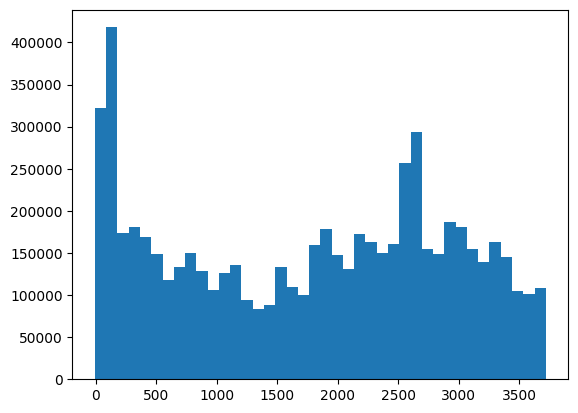

In [66]:
#redlight_df['issue_date'].value_counts().sort_index().plot.bar()

!pip install matplotlib
import matplotlib
import matplotlib.pyplot as plt

matplotlib.pyplot.hist(redlight_df['issue_date'], bins=40, color=None, edgecolor=None, label=None, density=False)

